# Topografía de la Tierra (v1) · cobertura completa, análogos conocidos y relieve local
**NASA Space Apps Challenge 2026** · Amplía `topografia_v0`:

| Cambio | v0 | v1 |
|---|---|---|
| Teselas por región | máximo 6 (las de más solape) | **todas** (Argelia, Riad, Sinkiang, Groenlandia… completas) |
| Qué se mide | regiones candidatas | regiones candidatas **+ análogos conocidos** de la ficha (círculo de 10 km) |
| Medidas | pendiente a 30 m y ~240 m | pendiente a 30 m y ~240 m **+ relieve local** (desnivel en ~1,2 km, a ~240 m) |

**Datos**: NASA ASTER GDEM v3 (`ASTGTM` v003), teselas de 1° × 1° a 30 m.

**Pensado para no agotar la RAM ni el disco**:
- Se procesa **una tesela cada vez** (~50 MB en memoria); al terminar se libera la memoria y se borra el archivo temporal.
- En Drive solo queda un resumen de unos KB por tesela en `03_datos/cache_api/topografia_v1/`.
- Cada ejecución trabaja como mucho `MAX_MINUTOS` (40 min por defecto) y se para sola. **Si al final pone «⏸ Quedan teselas
  pendientes», vuelve a ejecutar la sección 3** (o el notebook entero): continúa donde lo dejó, sin repetir nada.
- Si Colab se desconecta, no se pierde nada de lo ya guardado.

## 0. Instalación

In [3]:
!pip install -q earthaccess rasterio

## 1. Configuración

In [4]:
import os, re, gc, json, time, glob, datetime, unicodedata
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import earthaccess, rasterio
from rasterio import features
from scipy import ndimage
from shapely.geometry import shape, box, Point
from shapely import affinity
from IPython.display import display
from google.colab import drive, userdata

drive.mount("/content/drive")
for raiz in ["/content/drive/MyDrive", "/content/drive/My Drive"]:
    if os.path.isdir(raiz):
        break
BASE = f"{raiz}/Hackathon Nasa"
VERSION = "topografia_v1"
RES, WEB = f"{BASE}/04_resultados/{VERSION}", f"{BASE}/06_web/{VERSION}"
CACHE = f"{BASE}/03_datos/cache_api/topografia_v1"
TMP = "/content/tmp/topografia"
for d in (RES, WEB, CACHE, TMP):
    os.makedirs(d, exist_ok=True)

# --- Parámetros de las tandas ---
MAX_MINUTOS = 40                     # tiempo máximo por ejecución; luego se para y guarda (vuelve a ejecutar para seguir)
RADIO_ANALOGO_KM = 10                # círculo alrededor de cada análogo conocido
LADO_RELIEVE_M = 1200                # ventana del relieve local (desnivel máximo − mínimo)
PASO_BIN = 0.25; BINS = np.arange(0, 90 + PASO_BIN, PASO_BIN)        # pendiente (grados)
PASO_REL = 5; BINS_REL = np.arange(0, 3000 + PASO_REL, PASO_REL)      # relieve local (m)

FIGURAS = f"{RES}/figuras"; os.makedirs(FIGURAS, exist_ok=True)
_mostrar = getattr(plt, "_show_original", plt.show); plt._show_original = _mostrar
_n_fig = [0]
def _mostrar_y_guardar(*a, **k):
    fig = plt.gcf()
    if fig.axes:
        _n_fig[0] += 1
        titulo = next((ax.get_title() for ax in fig.axes if ax.get_title()), "figura")
        slug = re.sub(r"[^a-zA-Z0-9]+", "_", unicodedata.normalize("NFKD", titulo).encode("ascii", "ignore").decode()).strip("_").lower()[:50]
        fig.savefig(f"{FIGURAS}/fig_{_n_fig[0]:02d}_{slug}.png", dpi=80, bbox_inches="tight")
    _mostrar(*a, **k)
plt.show = _mostrar_y_guardar

os.environ["EARTHDATA_USERNAME"] = userdata.get("EARTHDATA_USERNAME")
os.environ["EARTHDATA_PASSWORD"] = userdata.get("EARTHDATA_PASSWORD")
auth = earthaccess.login(strategy="environment")
SESION = earthaccess.get_requests_https_session()
entrada = json.load(open(f"{BASE}/06_web/manifest.json", encoding="utf-8"))
print("Earthdata:", auth.authenticated, "| cuerpos:", {k: v["carpeta"] for k, v in entrada["cuerpos"].items()})

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Earthdata: True | cuerpos: {'marte': 'v1.3', 'luna': 'luna_v0.3'}


## 2. Qué se mide: regiones candidatas (completas) y análogos conocidos
Los análogos conocidos salen de `analogos.geojson` de cada cuerpo (los verificados de la ficha). Cada uno se mide en un círculo de 10 km.

In [5]:
def nombre_tesela(lat0, lon0):
    return f"{'N' if lat0 >= 0 else 'S'}{abs(lat0):02d}{'E' if lon0 >= 0 else 'W'}{abs(lon0):03d}"

def teselas_de(g):
    oeste, sur, este, norte = g.bounds
    out = []
    for la in range(int(np.floor(sur)), int(np.ceil(norte))):
        if not -83 <= la < 83:
            continue
        for lo in range(int(np.floor(oeste)), int(np.ceil(este))):
            if g.intersects(box(lo, la, lo + 1, la + 1)):
                out.append((nombre_tesela(la, lo), la, lo))
    return out

def circulo_grados(lon, lat, radio_km):
    """Círculo de radio_km alrededor de un punto, como elipse en grados (vale para radios pequeños)."""
    rlat = radio_km / 111.32
    return affinity.scale(Point(lon, lat).buffer(rlat, 64), xfact=1 / max(np.cos(np.radians(lat)), 0.05), yfact=1)

filas = []
for cuerpo in ["luna", "marte"]:
    info = entrada["cuerpos"][cuerpo]
    gj = json.load(open(f"{BASE}/06_web/{info['carpeta']}/regiones.geojson", encoding="utf-8"))
    for ft in gj["features"]:
        g = shape(ft["geometry"]); p = ft["properties"]
        filas.append({"region_id": p["id"], "cuerpo": cuerpo, "tipo": "region_candidata", "region": p.get("region"), "geom": g})
    an = json.load(open(f"{BASE}/06_web/{info['carpeta']}/analogos.geojson", encoding="utf-8"))
    for ft in an["features"]:
        p = ft["properties"]
        ok = (p.get("tipo") in ("analogo_luna", "impacto")) if cuerpo == "luna" else (p.get("verificacion") == "verificada")
        if not ok or not ft.get("geometry"):
            continue
        lon, lat = ft["geometry"]["coordinates"][:2]
        slug = re.sub(r"[^a-z0-9]+", "-", unicodedata.normalize("NFKD", p["nombre"]).encode("ascii", "ignore").decode().lower()).strip("-")[:40]
        filas.append({"region_id": f"analogo-{cuerpo}-{slug}", "cuerpo": cuerpo, "tipo": "analogo_conocido", "region": p["nombre"],
                      "geom": circulo_grados(lon, lat, RADIO_ANALOGO_KM)})
regiones = pd.DataFrame(filas)
regiones["teselas"] = regiones.geom.map(teselas_de)
regiones = regiones[regiones.teselas.str.len() > 0].reset_index(drop=True)
regiones.drop(columns="geom").assign(n_teselas=regiones.teselas.str.len()).drop(columns="teselas") \
    .to_csv(f"{RES}/regiones_v1.csv", index=False)

trabajo = [(r.region_id, t) for r in regiones.itertuples() for t in r.teselas]
hecha = lambda rid, t: os.path.exists(f"{CACHE}/{rid}__{t[0]}.npz")
hechas = sum(hecha(rid, t) for rid, t in trabajo)
print(f"{(regiones.tipo == 'region_candidata').sum()} regiones candidatas + {(regiones.tipo == 'analogo_conocido').sum()} análogos conocidos")
print(f"{len(trabajo)} teselas en total | ya procesadas: {hechas} | pendientes: {len(trabajo) - hechas}")
print(f"Pendiente: ~{(len(trabajo) - hechas) * 25 / 1000:.0f} GB de descarga temporal (no ocupa Drive) y "
      f"~{(len(trabajo) - hechas) * 4 / 60:.0f} min aprox.; en Drive solo ~{(len(trabajo) - hechas) * 12 / 1000:.0f} MB")
display(regiones.assign(n_teselas=regiones.teselas.str.len()).sort_values("n_teselas", ascending=False)[["region_id", "region", "tipo", "n_teselas"]].head(12))

41 regiones candidatas + 15 análogos conocidos
1053 teselas en total | ya procesadas: 0 | pendientes: 1053
Pendiente: ~26 GB de descarga temporal (no ocupa Drive) y ~70 min aprox.; en Drive solo ~13 MB


,region_id,region,tipo,n_teselas
38,marte_arido-1,Argelia,region_candidata,557
39,marte_arido-2,"Provincia de Riad, Arabia Saudita",region_candidata,75
41,marte_arido-4,"Sinkiang, China",region_candidata,75
27,marte_polar-1,Groenlandia,region_candidata,71
35,marte_altura-1,"Sinkiang, China",region_candidata,40
29,marte_polar-3,"Nunavut, Canadá",region_candidata,22
0,luna-1,"Afar, Etiopía",region_candidata,19
40,marte_arido-3,"Región de Antofagasta, Chile",region_candidata,16
43,marte_arido-6,"Provincia Oriental, Arabia Saudita",region_candidata,11
46,marte_arido-9,"Mongolia Interior, China",region_candidata,11


## 3. Procesado por tandas (ASTER GDEM v3)
Para cada tesela: descarga a la carpeta temporal → pendiente a 30 m → promedio a ~240 m → pendiente y relieve local a ~240 m →
histogramas a Drive → borrado del archivo y liberación de memoria. **Vuelve a ejecutar esta celda si queda trabajo pendiente.**

In [10]:
M_POR_SEG = 30.87                                         # metros por segundo de arco (latitud)

def pendiente(z, dy, dx_filas):
    gy, gx = np.gradient(z)
    gx /= np.asarray(dx_filas, dtype="float32")[:, None]; gy /= np.float32(dy)
    np.hypot(gx, gy, out=gx); del gy
    return np.degrees(np.arctan(gx, out=gx), out=gx)

def impar(n):
    n = max(int(round(n)), 3)                             # como mínimo 3 × 3 píxeles
    return n if n % 2 else n + 1

def relieve(z, dy, dx):
    """Desnivel (máximo − mínimo) en una ventana de ~LADO_RELIEVE_M; NaN si la ventana toca huecos de datos."""
    tam = (impar(LADO_RELIEVE_M / dy), impar(LADO_RELIEVE_M / dx))
    hueco = ~np.isfinite(z)
    zf = np.where(hueco, np.nanmean(z) if np.isfinite(z).any() else 0, z)
    r = ndimage.maximum_filter(zf, size=tam) - ndimage.minimum_filter(zf, size=tam)
    r[ndimage.maximum_filter(hueco.astype(np.uint8), size=tam) > 0] = np.nan
    return r

def urls_aster(geom):
    oeste, sur, este, norte = geom.bounds
    urls = {}
    for g in earthaccess.search_data(short_name="ASTGTM", version="003", bounding_box=(oeste, sur, este, norte)):
        for u in g.data_links():
            m = re.search(r"ASTGTMV003_([NS]\d{2}[EW]\d{3})_dem\.tif$", u)
            if m:
                urls[m.group(1)] = u
    return urls

def descargar(url, destino):
    with SESION.get(url, stream=True, timeout=300) as r:
        r.raise_for_status()
        with open(destino, "wb") as f:
            for trozo in r.iter_content(1 << 22):
                f.write(trozo)

def procesar(geom, tesela, url):
    nombre = tesela[0]
    ruta = f"{TMP}/{nombre}_dem.tif"
    descargar(url, ruta)
    try:
        with rasterio.open(ruta) as src:
            z = src.read(1).astype("float32"); tr = src.transform
    finally:
        os.remove(ruta)
    z[z < -500] = np.nan
    mascara = features.geometry_mask([geom], out_shape=z.shape, transform=tr, invert=True)
    if not mascara.any():
        return {"sin_dato": True}
    lat_filas = tr.f + tr.e * (np.arange(z.shape[0]) + 0.5)
    dx = M_POR_SEG * abs(tr.a) * 3600 * np.cos(np.radians(lat_filas)); dy = M_POR_SEG * abs(tr.e) * 3600
    s30 = pendiente(z, dy, dx)
    ok = mascara & np.isfinite(s30)
    h30 = np.histogram(s30[ok], BINS)[0]; n30 = int(ok.sum())
    zr = z[ok]; z_sum, z_n = float(np.nansum(zr)), int(np.isfinite(zr).sum())
    z_min, z_max = (float(np.nanmin(zr)), float(np.nanmax(zr))) if zr.size else (np.nan, np.nan)
    del s30, ok, zr
    n = (z.shape[0] // 8) * 8, (z.shape[1] // 8) * 8                  # ~240 m: bloques de 8 × 8
    z8 = np.nanmean(z[:n[0], :n[1]].reshape(n[0] // 8, 8, n[1] // 8, 8), axis=(1, 3))
    m8 = mascara[:n[0], :n[1]].reshape(n[0] // 8, 8, n[1] // 8, 8).mean(axis=(1, 3)) >= 0.5
    del z, mascara
    dx8 = dx[:n[0]].reshape(-1, 8).mean(1) * 8
    s240 = pendiente(z8, dy * 8, dx8)
    rel = relieve(z8, dy * 8, float(np.mean(dx8)))
    ok240, okr = m8 & np.isfinite(s240), m8 & np.isfinite(rel)
    out = {"h30": h30, "n30": n30, "h240": np.histogram(s240[ok240], BINS)[0],
           "hrel": np.histogram(np.clip(rel[okr], 0, BINS_REL[-1] - 0.01), BINS_REL)[0],
           "z_sum": z_sum, "z_n": z_n, "z_min": z_min, "z_max": z_max}
    del z8, m8, s240, rel
    return out

t0, nuevas, errores, parado = time.time(), 0, 0, False
for r in regiones.itertuples():
    pendientes = [t for t in r.teselas if not hecha(r.region_id, t)]
    if not pendientes:
        continue
    if (time.time() - t0) / 60 > MAX_MINUTOS:
        parado = True; break
    try:
        urls = urls_aster(r.geom)
    except Exception as e:
        print(f"  ⚠ búsqueda {r.region_id}: {e!r} (se reintentará)"); errores += 1; continue
    for t in pendientes:
        if (time.time() - t0) / 60 > MAX_MINUTOS:
            parado = True; break
        destino = f"{CACHE}/{r.region_id}__{t[0]}.npz"
        if t[0] not in urls:                                     # mar o fuera de cobertura de ASTER
            np.savez(destino, sin_dato=True); continue
        try:
            np.savez(destino, **procesar(r.geom, t, urls[t[0]]))
            nuevas += 1
        except Exception as e:
            errores += 1
            print(f"  ⚠ {r.region_id} {t[0]}: {e!r} (se reintentará en la próxima ejecución)")
        gc.collect()
        if nuevas % 25 == 0 and nuevas:
            hechas = sum(hecha(rid, tt) for rid, tt in trabajo)
            print(f"  {hechas}/{len(trabajo)} teselas · {(time.time() - t0) / 60:.0f} min · ahora: {r.region_id}")
    if parado:
        break

hechas = sum(hecha(rid, t) for rid, t in trabajo)
print(f"\nNuevas en esta ejecución: {nuevas} · errores: {errores} · total procesadas: {hechas} de {len(trabajo)} "
      f"({(time.time() - t0) / 60:.0f} min)")
TERMINADO = hechas == len(trabajo)
print("✅ Todas las teselas procesadas." if TERMINADO else "⏸ Quedan teselas pendientes: vuelve a ejecutar esta celda (o el notebook) para continuar.")

  848/1053 teselas · 1 min · ahora: marte_arido-2
  873/1053 teselas · 2 min · ahora: marte_arido-2
  898/1053 teselas · 3 min · ahora: marte_arido-2
  923/1053 teselas · 5 min · ahora: marte_arido-3
  948/1053 teselas · 6 min · ahora: marte_arido-4
  973/1053 teselas · 7 min · ahora: marte_arido-4
  998/1053 teselas · 8 min · ahora: marte_arido-4
  1023/1053 teselas · 9 min · ahora: marte_arido-8
  1048/1053 teselas · 11 min · ahora: analogo-marte-valles-secos-de-mcmurdo

Nuevas en esta ejecución: 230 · errores: 0 · total procesadas: 1053 de 1053 (11 min)
✅ Todas las teselas procesadas.


## 4. Resumen por región y por análogo

In [11]:
def estadisticas(h, bins=BINS, umbrales=(5, 10, 15)):
    h = np.asarray(h, float); tot = h.sum()
    if tot == 0:
        return dict(mediana=np.nan, p90=np.nan, **{f"pct_lt{u}": np.nan for u in umbrales})
    acum = np.cumsum(h) / tot
    q = lambda p: float(bins[1:][np.searchsorted(acum, p)])
    paso = bins[1] - bins[0]
    return dict(mediana=q(0.5), p90=q(0.9), **{f"pct_lt{u}": float(acum[int(round(u / paso)) - 1] * 100) for u in umbrales})

filas, HIST = [], {}
for r in regiones.itertuples():
    h30 = np.zeros(len(BINS) - 1); h240 = np.zeros(len(BINS) - 1); hrel = np.zeros(len(BINS_REL) - 1)
    zs = zn = 0; zmin, zmax = np.inf, -np.inf; hechas_r = 0
    for t in r.teselas:
        ruta = f"{CACHE}/{r.region_id}__{t[0]}.npz"
        if not os.path.exists(ruta):
            continue
        hechas_r += 1
        d = np.load(ruta)
        if "sin_dato" in d.files:
            continue
        h30 += d["h30"]; h240 += d["h240"]; hrel += d["hrel"]; zs += float(d["z_sum"]); zn += int(d["z_n"])
        zmin = min(zmin, float(d["z_min"])); zmax = max(zmax, float(d["z_max"]))
    HIST[r.region_id] = (h240, hrel)
    e30, e240, erel = estadisticas(h30), estadisticas(h240), estadisticas(hrel, BINS_REL, (50, 100, 200))
    filas.append({"region_id": r.region_id, "cuerpo": r.cuerpo, "tipo": r.tipo, "region": r.region,
                  "teselas_hechas": f"{hechas_r}/{len(r.teselas)}", "completa": hechas_r == len(r.teselas),
                  "elev_media_m": round(zs / zn) if zn else np.nan, "elev_min_m": round(zmin) if zn else np.nan,
                  "elev_max_m": round(zmax) if zn else np.nan,
                  **{f"{k}_30m": round(v, 1) for k, v in e30.items()}, **{f"{k}_240m": round(v, 1) for k, v in e240.items()},
                  **{f"relieve_{k}": round(v, 1) for k, v in erel.items()}})
topo = pd.DataFrame(filas)
topo.to_csv(f"{RES}/topografia_regiones_v1.csv", index=False)
print("Regiones completas:", int(topo.completa.sum()), "de", len(topo))
cols = ["region_id", "region", "teselas_hechas", "mediana_240m", "pct_lt10_240m", "relieve_mediana", "relieve_p90"]
display(topo[topo.tipo == "region_candidata"][cols])
display(topo[topo.tipo == "analogo_conocido"][cols])

Regiones completas: 56 de 56


,region_id,region,teselas_hechas,mediana_240m,pct_lt10_240m,relieve_mediana,relieve_p90
0,luna-1,"Afar, Etiopía",19/19,1.8,90.7,40.0,180.0
1,luna-2,"Gobernacion de Rif Dimashq, Siria",10/10,1.2,97.9,25.0,85.0
2,luna-3,"Provincia de Medina, Arabia Saudita",5/5,1.2,98.7,25.0,60.0
3,luna-4,"Afar, Etiopía",5/5,1.0,97.8,20.0,90.0
4,luna-5,"Condado de Marsabit, Kenia",4/4,1.0,98.6,25.0,70.0
5,luna-6,"Provincia de La Meca, Arabia Saudita",4/4,1.0,99.8,20.0,50.0
6,luna-7,Islandia,6/6,2.0,88.7,60.0,185.0
7,luna-8,"Afar, Etiopía",3/3,1.5,95.7,35.0,125.0
8,luna-9,"Provincia de Tabuk, Arabia Saudita",3/3,3.0,90.4,70.0,155.0
9,luna-10,"Tibesti, Chad",4/4,6.2,69.3,135.0,330.0


,region_id,region,teselas_hechas,mediana_240m,pct_lt10_240m,relieve_mediana,relieve_p90
20,analogo-luna-craters-of-the-moon-idaho,"Craters of the Moon, Idaho",1/1,1.2,94.0,25.0,120.0
21,analogo-luna-kilauea-hawai,"Kīlauea, Hawái",1/1,2.8,98.6,55.0,105.0
22,analogo-luna-pinacate-sonora,"Pinacate, Sonora",1/1,3.8,92.6,100.0,210.0
23,analogo-luna-askja-islandia,"Askja, Islandia",2/2,5.0,72.7,155.0,400.0
24,analogo-luna-lanzarote-timanfaya,Lanzarote – Timanfaya,2/2,2.8,90.9,80.0,200.0
25,analogo-luna-mauna-kea-hawai,"Mauna Kea, Hawái",1/1,12.5,30.2,265.0,390.0
26,analogo-luna-meteor-crater-arizona,"Meteor Crater, Arizona",4/4,1.0,99.6,25.0,35.0
48,analogo-marte-cuenca-de-qaidam-occidental-lenghu,Cuenca de Qaidam occidental (Lenghu),1/1,1.2,100.0,30.0,70.0
49,analogo-marte-isla-axel-heiberg-gypsum-hill-m-...,Isla Axel Heiberg (Gypsum Hill / M.A.R.S.),2/2,10.8,47.2,260.0,440.0
50,analogo-marte-isla-devon-haughton-mars-project,Isla Devon (Haughton-Mars Project),2/2,3.5,96.4,65.0,100.0


## 5. Cambios respecto a v0 (6 teselas por región)
¿Cambia la pendiente de las regiones grandes al medirlas completas?

,region_id,cobertura_teselas,mediana_240m_v0,pct_lt10_240m_v0,teselas_hechas,mediana_240m_v1,pct_lt10_240m_v1,cambio_pct_lt10
31,marte_arido-1,0.01,1.0,99.7,557/557,1.2,98.4,-1.3
32,marte_arido-2,0.12,0.8,98.8,75/75,1.0,99.5,0.7
34,marte_arido-4,0.12,1.5,99.6,75/75,1.5,98.1,-1.5
20,marte_polar-1,0.16,4.2,75.0,71/71,3.8,79.8,4.8
28,marte_altura-1,0.27,4.0,78.9,40/40,5.2,66.9,-12.0
22,marte_polar-3,0.60,2.8,83.5,22/22,3.5,80.0,-3.5
33,marte_arido-3,0.64,2.5,93.9,16/16,2.5,91.6,-2.3
0,luna-1,0.77,1.8,90.8,19/19,1.8,90.7,-0.1
39,marte_arido-9,0.84,1.0,99.6,11/11,1.0,99.5,-0.1
36,marte_arido-6,0.93,1.0,100.0,11/11,1.0,100.0,0.0


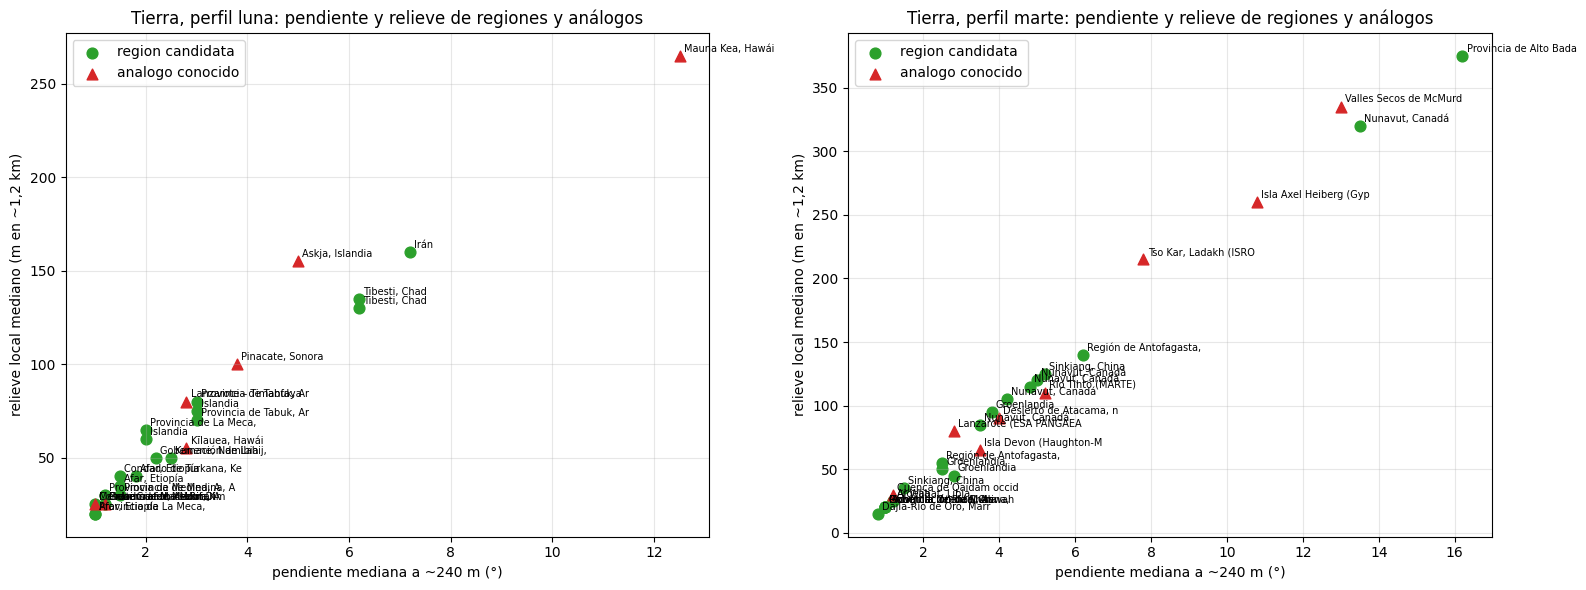

In [12]:
v0 = f"{BASE}/04_resultados/topografia_v0/topografia_regiones.csv"
if os.path.exists(v0):
    a = pd.read_csv(v0)[["region_id", "cobertura_teselas", "mediana_240m", "pct_lt10_240m"]]
    comp = a.merge(topo[["region_id", "teselas_hechas", "mediana_240m", "pct_lt10_240m"]], on="region_id", suffixes=("_v0", "_v1"))
    comp["cambio_pct_lt10"] = (comp.pct_lt10_240m_v1 - comp.pct_lt10_240m_v0).round(1)
    display(comp.sort_values("cobertura_teselas").head(15))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, cuerpo in zip(axes, ["luna", "marte"]):
    sel = topo[topo.cuerpo == cuerpo]
    for tipo, color, mk in (("region_candidata", "tab:green", "o"), ("analogo_conocido", "tab:red", "^")):
        s = sel[sel.tipo == tipo]
        ax.scatter(s.mediana_240m, s.relieve_mediana, c=color, marker=mk, s=60, label=tipo.replace("_", " "))
        for r in s.itertuples():
            ax.annotate(str(r.region)[:22], (r.mediana_240m, r.relieve_mediana), fontsize=7, xytext=(3, 3), textcoords="offset points")
    ax.set_xlabel("pendiente mediana a ~240 m (°)"); ax.set_ylabel("relieve local mediano (m en ~1,2 km)")
    ax.set_title(f"Tierra, perfil {cuerpo}: pendiente y relieve de regiones y análogos"); ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()

## 6. Capa para la web y registro

In [13]:
def limpio(v):
    if isinstance(v, (float, np.floating)): return None if np.isnan(v) else float(v)
    if isinstance(v, (np.integer,)): return int(v)
    if isinstance(v, (np.bool_,)): return bool(v)
    return v

salida = {"version": VERSION, "unidades": {"pendiente": "grados", "relieve": "m (máximo − mínimo en ~1,2 km)", "elevacion": "m"},
          "escalas": {"30m": "ASTER GDEM v3 a resolución completa", "240m": "ASTER promediado 8×8 (pendiente y relieve)"},
          "regiones": {r["region_id"]: {k: limpio(v) for k, v in r.items() if k != "region_id"} for r in topo.to_dict("records")},
          "nota": "unir con regiones.geojson de cada cuerpo por region_id; los análogos conocidos tienen id analogo-<cuerpo>-<nombre>"}
json.dump(salida, open(f"{WEB}/topografia.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2, allow_nan=False)
if TERMINADO:
    entrada = json.load(open(f"{BASE}/06_web/manifest.json", encoding="utf-8"))
    entrada.setdefault("capas", {})["topografia"] = {"version": VERSION, "carpeta": VERSION, "archivo": f"{VERSION}/topografia.json"}
    json.dump(entrada, open(f"{BASE}/06_web/manifest.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2)
registro = {"version": VERSION, "fecha": datetime.datetime.now().isoformat(timespec="seconds"),
            "datos": "NASA ASTER GDEM v3 (ASTGTM v003), doi:10.5067/ASTER/ASTGTM.003",
            "parametros": {"radio_analogo_km": RADIO_ANALOGO_KM, "lado_relieve_m": LADO_RELIEVE_M, "max_minutos": MAX_MINUTOS},
            "progreso": f"{sum(hecha(rid, t) for rid, t in trabajo)}/{len(trabajo)} teselas",
            "limitaciones": ["a 30 m el ruido vertical de ASTER infla la pendiente del terreno llano: comparar a 240 m",
                             "ASTER no cubre más allá de 83° N/S"]}
json.dump(registro, open(f"{RES}/registro_{VERSION}.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2, default=str)
print("Guardado.", "Capa web registrada en el manifest." if TERMINADO else "La capa web se registrará cuando estén todas las teselas.")

Guardado. Capa web registrada en el manifest.


## 7. Conclusiones
*Rellenar cuando estén todas las teselas.*